<a href="https://colab.research.google.com/github/rtkmilaa/Ratih-Kamila-Khairani/blob/main/Ratih_Kamila_Khairani_055283881_Machine_Learning_Tugas_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 3 – Implementasi Unsupervised Learning
## Segmentasi Pelanggan Berdasarkan Analisis Kepribadian dan Perilaku Pembelian
<p>
Nama: Ratih Kamila Khairani<p>
NIM: 055283881<P>
Prodi: Sains DATA<P>
Dataset: `cpa.csv` <p>
Algoritma: K-Means  
Evaluasi: Elbow Method dan Silhouette Score  
Visualisasi: PCA 2D


In [1]:
# 1. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## Step 1 – Load dataset

In [2]:
#sesuaikan path file
DATA_PATH = 'cpa.csv'

# File cpa.csv pada tugas ini berformat tab-separated.
df = pd.read_csv(DATA_PATH, sep='\\t')

print('Ukuran dataset:', df.shape)
display(df.head())

Ukuran dataset: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## Step 2 – Eksplorasi data awal

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,2240.0,NaN,NaN,NaN,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,NaN,NaN,NaN,1968.805804,11.984069,1893.0,1959.0,1970.0,1977.0,1996.0
Education,2240,5,Graduation,1127,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,2240,8,Married,864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income,2216.0,NaN,NaN,NaN,52247.251354,25173.076661,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,NaN,NaN,NaN,0.444196,0.538398,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,NaN,NaN,NaN,0.50625,0.544538,0.0,0.0,0.0,1.0,2.0
Dt_Customer,2240,663,31-08-2012,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Recency,2240.0,NaN,NaN,NaN,49.109375,28.962453,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,NaN,NaN,NaN,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0


,Jumlah Missing Value
Income,24


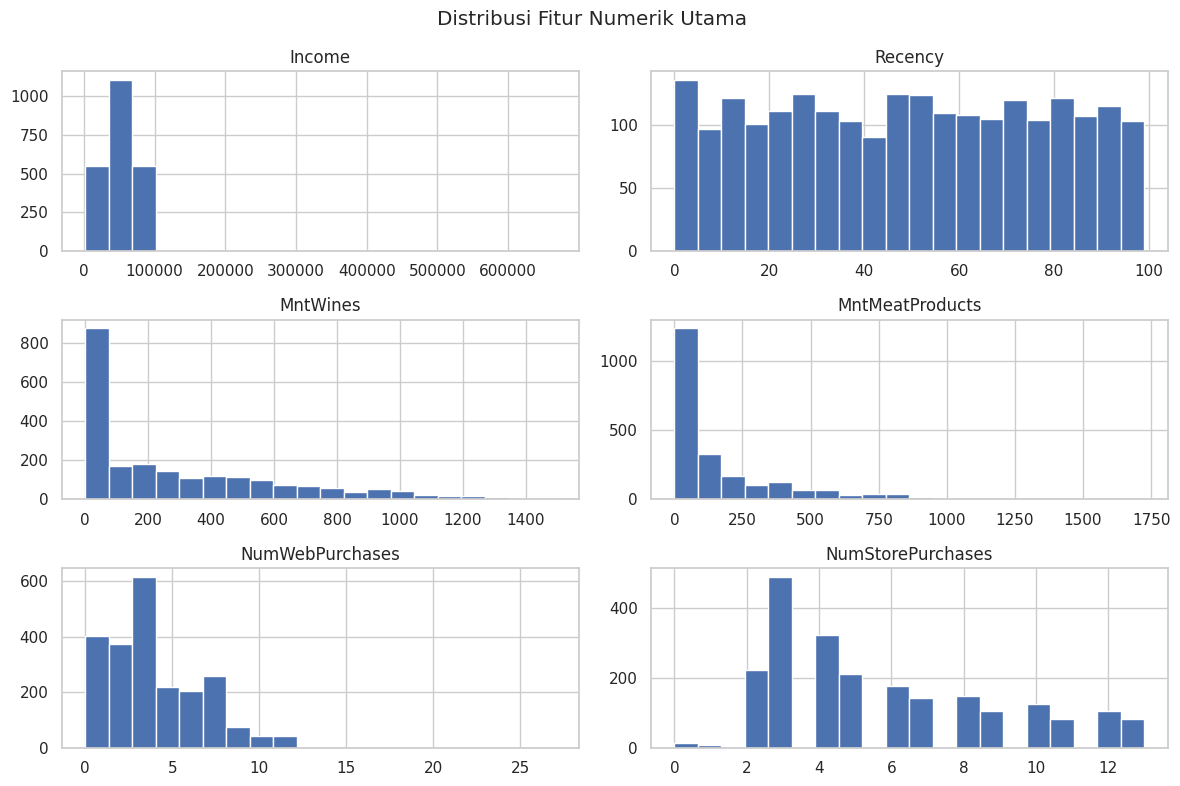

Jumlah data duplikat: 0


In [3]:
# Struktur data dan tipe setiap kolom
df.info()

# Statistik deskriptif
display(df.describe(include='all').T)

# Jumlah missing value
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame('Jumlah Missing Value'))

# Distribusi fitur utama
numeric_preview = ['Income', 'Recency', 'MntWines', 'MntMeatProducts',
                   'NumWebPurchases', 'NumStorePurchases']
df[numeric_preview].hist(figsize=(12, 8), bins=20)
plt.suptitle('Distribusi Fitur Numerik Utama')
plt.tight_layout()
plt.show()

print('Jumlah data duplikat:', df.duplicated().sum())

**Hasil eksplorasi:** Dataset memiliki 2.240 baris dan 29 kolom. Terdapat 24 missing value pada kolom `Income`, sedangkan kolom lainnya tidak memiliki missing value. Kolom `ID` tidak digunakan sebagai fitur karena hanya merupakan identitas pelanggan. Kolom `Z_CostContact` dan `Z_Revenue` juga tidak digunakan karena nilainya konstan.

## Step 3 – Identifikasi kolom numerik dan kategori

In [4]:
# Kolom identitas dan kolom konstan dikeluarkan dari fitur clustering.
drop_cols = ['ID', 'Dt_Customer', 'Z_CostContact', 'Z_Revenue']
data_model = df.drop(columns=drop_cols, errors='ignore').copy()

numeric_cols = data_model.select_dtypes(include=np.number).columns.tolist()
categorical_cols = data_model.select_dtypes(include=['object', 'category']).columns.tolist()

print('Fitur numerik:', numeric_cols)
print('Fitur kategori:', categorical_cols)
print('Jumlah fitur numerik:', len(numeric_cols))
print('Jumlah fitur kategori:', len(categorical_cols))

Fitur numerik: ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response']
Fitur kategori: ['Education', 'Marital_Status']
Jumlah fitur numerik: 23
Jumlah fitur kategori: 2


## Step 4 – Imputasi missing value

In [5]:
# Numerik: median agar lebih tahan terhadap nilai ekstrem.
# Kategori: modus karena mengganti nilai kosong dengan kategori paling sering muncul.
numeric_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

X_num = pd.DataFrame(
    numeric_imputer.fit_transform(data_model[numeric_cols]),
    columns=numeric_cols,
    index=data_model.index
)

if categorical_cols:
    X_cat_raw = pd.DataFrame(
        categorical_imputer.fit_transform(data_model[categorical_cols]),
        columns=categorical_cols,
        index=data_model.index
    )
else:
    X_cat_raw = pd.DataFrame(index=data_model.index)

print('Missing value numerik setelah imputasi:', int(X_num.isnull().sum().sum()))
print('Missing value kategori setelah imputasi:', int(X_cat_raw.isnull().sum().sum()))

Missing value numerik setelah imputasi: 0
Missing value kategori setelah imputasi: 0


## Step 5 – Encoding fitur kategori

In [6]:
# One-Hot Encoding mengubah kategori menjadi kolom indikator 0 dan 1.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # kompatibilitas dengan versi scikit-learn lama
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

if categorical_cols:
    X_cat_encoded_array = encoder.fit_transform(X_cat_raw)
    encoded_names = encoder.get_feature_names_out(categorical_cols)
    X_cat_encoded = pd.DataFrame(
        X_cat_encoded_array,
        columns=encoded_names,
        index=data_model.index
    )
else:
    X_cat_encoded = pd.DataFrame(index=data_model.index)

print('Jumlah kolom hasil encoding:', X_cat_encoded.shape[1])
display(X_cat_encoded.head())

Jumlah kolom hasil encoding: 13


,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Menggabungkan data numerik dan hasil encoding

In [7]:
X = pd.concat([X_num, X_cat_encoded], axis=1)
print('Ukuran data setelah preprocessing awal:', X.shape)
display(X.head())

Ukuran data setelah preprocessing awal: (2240, 36)


,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,Education_Master,Education_PhD,Marital_Status_Absurd,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1957.0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,1954.0,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1965.0,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984.0,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1981.0,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## Step 6 – Scaling data

In [8]:
# StandardScaler menyetarakan skala fitur agar fitur berskala besar
# tidak mendominasi perhitungan jarak pada K-Means.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Ukuran matriks hasil scaling:', X_scaled.shape)
print('Rata-rata fitur pertama setelah scaling:', round(X_scaled[:, 0].mean(), 4))
print('Standar deviasi fitur pertama setelah scaling:', round(X_scaled[:, 0].std(), 4))

Ukuran matriks hasil scaling: (2240, 36)
Rata-rata fitur pertama setelah scaling: -0.0
Standar deviasi fitur pertama setelah scaling: 1.0


## Step 7 – Menentukan jumlah klaster optimal (Elbow dan Silhouette)

,Jumlah Cluster (k),Inertia,Silhouette Score
0,2,69214.271698,0.177918
1,3,65541.542212,0.107292
2,4,62964.772850,0.110778
3,5,60642.243909,0.125788
4,6,59210.643727,0.077022
5,7,57454.753362,0.104900
6,8,54846.687168,0.094595


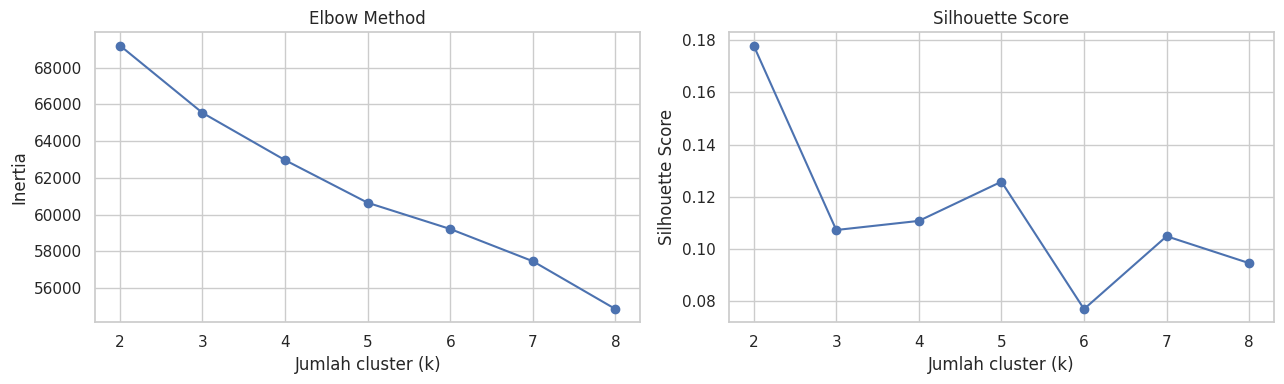

In [9]:
inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

evaluation = pd.DataFrame({
    'Jumlah Cluster (k)': list(k_values),
    'Inertia': inertias,
    'Silhouette Score': silhouette_scores
})
display(evaluation)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Jumlah cluster (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(list(k_values), silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah cluster (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

**Interpretasi pemilihan k:** Berdasarkan pengujian k = 2 sampai k = 8, nilai Silhouette Score tertinggi diperoleh pada k = 2 (sekitar 0,178). Oleh karena itu, jumlah klaster yang digunakan adalah **2 klaster**. Nilai silhouette yang relatif rendah menunjukkan bahwa pemisahan antar-klaster belum terlalu kuat, sehingga hasil segmentasi perlu ditafsirkan secara hati-hati.

## Step 8 – Melatih K-Means dengan jumlah klaster terpilih

In [10]:
optimal_k = 2
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Menambahkan label cluster ke data asli untuk kebutuhan profiling.
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

print('Jumlah pelanggan pada setiap cluster:')
display(df_clustered['Cluster'].value_counts().sort_index().to_frame('Jumlah Pelanggan'))
print('Silhouette Score untuk model akhir:',
      round(silhouette_score(X_scaled, cluster_labels), 4))

Jumlah pelanggan pada setiap cluster:


,Jumlah Pelanggan
Cluster,
0,1358
1,882


Silhouette Score untuk model akhir: 0.1779


## Step 9 – Visualisasi klaster dengan PCA 2D

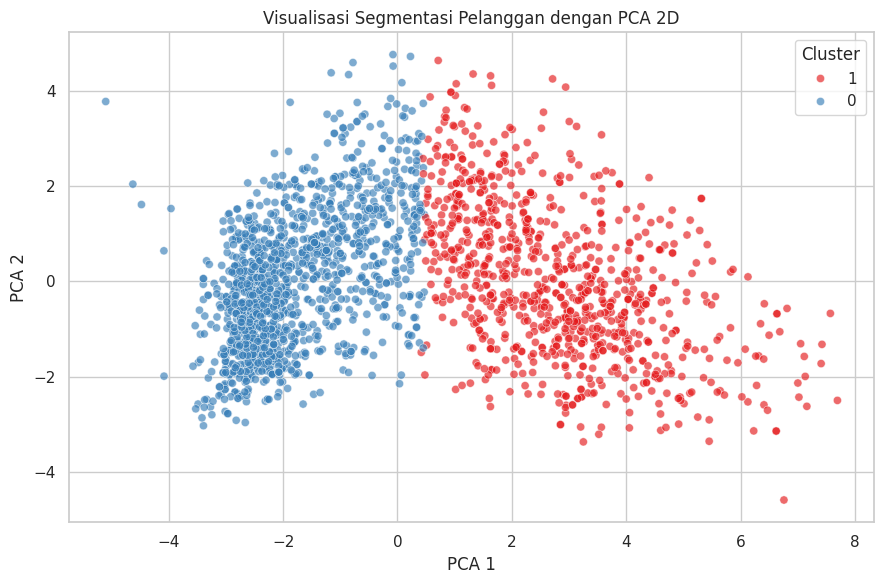

Total variasi yang dijelaskan PCA 2D: 24.32 %


In [11]:
# PCA mereduksi fitur berdimensi tinggi menjadi dua komponen untuk visualisasi.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'PCA 1': X_pca[:, 0],
    'PCA 2': X_pca[:, 1],
    'Cluster': cluster_labels.astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x='PCA 1', y='PCA 2',
                hue='Cluster', palette='Set1', alpha=0.65, s=35)
plt.title('Visualisasi Segmentasi Pelanggan dengan PCA 2D')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

print('Total variasi yang dijelaskan PCA 2D:',
      round(pca.explained_variance_ratio_.sum() * 100, 2), '%')

## Step 10 – Profiling cluster

In [12]:
# Rata-rata fitur numerik asli pada masing-masing cluster.
profile_numeric = df_clustered.groupby('Cluster')[numeric_cols].mean().round(2)
display(profile_numeric.T)

# Kategori yang paling sering muncul pada tiap cluster.
if categorical_cols:
    profile_categorical = df_clustered.groupby('Cluster')[categorical_cols].agg(
        lambda col: col.mode().iloc[0] if not col.mode().empty else np.nan
    )
    display(profile_categorical)

# Proporsi jumlah pelanggan per cluster.
cluster_pct = (
    df_clustered['Cluster'].value_counts(normalize=True).sort_index() * 100
).round(2)
display(cluster_pct.to_frame('Persentase Pelanggan (%)'))

Cluster,0,1
Year_Birth,1969.93,1967.08
Income,39151.26,72355.74
Kidhome,0.69,0.07
Teenhome,0.56,0.42
Recency,48.80,49.58
MntWines,107.17,606.89
MntFruits,6.73,56.43
MntMeatProducts,38.06,365.40
MntFishProducts,9.81,80.20
MntSweetProducts,6.87,58.15


,Education,Marital_Status
Cluster,,
0,Graduation,Married
1,Graduation,Married


,Persentase Pelanggan (%)
Cluster,
0,60.62
1,39.38


## Kesimpulan dan interpretasi

Berdasarkan hasil K-Means dengan 2 klaster, segmentasi pelanggan dapat dijelaskan sebagai berikut:

1. **Cluster 0 – Pelanggan dengan pengeluaran relatif rendah.** Rata-rata pendapatan sekitar 39.151, pengeluaran untuk produk wine sekitar 107, dan pengeluaran untuk produk daging sekitar 38. Kelompok ini memiliki rata-rata kunjungan web bulanan sekitar 6,4 kali. Segmen ini dapat menjadi sasaran promosi produk terjangkau, paket hemat, dan komunikasi pemasaran digital.

2. **Cluster 1 – Pelanggan dengan pendapatan dan pengeluaran relatif tinggi.** Rata-rata pendapatan sekitar 72.356, pengeluaran untuk produk wine sekitar 607, dan pengeluaran untuk produk daging sekitar 365. Kelompok ini juga memiliki rata-rata pembelian di toko dan katalog lebih tinggi serta kunjungan web lebih rendah. Segmen ini berpotensi menjadi sasaran program loyalitas, penawaran produk premium, dan rekomendasi produk sesuai preferensi.

**Kesimpulan umum:** K-Means membagi pelanggan menjadi dua kelompok utama berdasarkan karakteristik demografis dan perilaku pembelian. Cluster 0 menggambarkan pelanggan dengan pengeluaran relatif rendah, sedangkan Cluster 1 menggambarkan pelanggan dengan pendapatan dan pengeluaran relatif tinggi. Hasil ini dapat membantu perusahaan menyusun strategi pemasaran yang lebih sesuai dengan karakteristik setiap kelompok.

**Catatan evaluasi:** Silhouette Score sekitar 0,178 menunjukkan kualitas pemisahan klaster masih terbatas. Segmentasi ini dapat dikembangkan lebih lanjut dengan pemilihan fitur, penanganan outlier, atau mencoba algoritma clustering lain. Hasil cluster bukan label pasti tentang kepribadian individu, melainkan pengelompokan berdasarkan fitur yang tersedia.